# libraries

In [6]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns



# load dataset

In [8]:
data=pd.read_csv("C:/Users/Acer/OneDrive/Attachments/Desktop/smart-industrial-predictive-maintenance/data/ai4i2020.csv")
df=pd.DataFrame(data)

# the dataset

In [9]:
df.head(5)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [10]:
df.shape

(10000, 14)

In [13]:
df.columns.tolist()

['UDI',
 'Product ID',
 'Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

# data quality

In [17]:
df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [22]:
result=df["Type"].value_counts()
result

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Text(0, 0.5, 'count of machine in each Type')

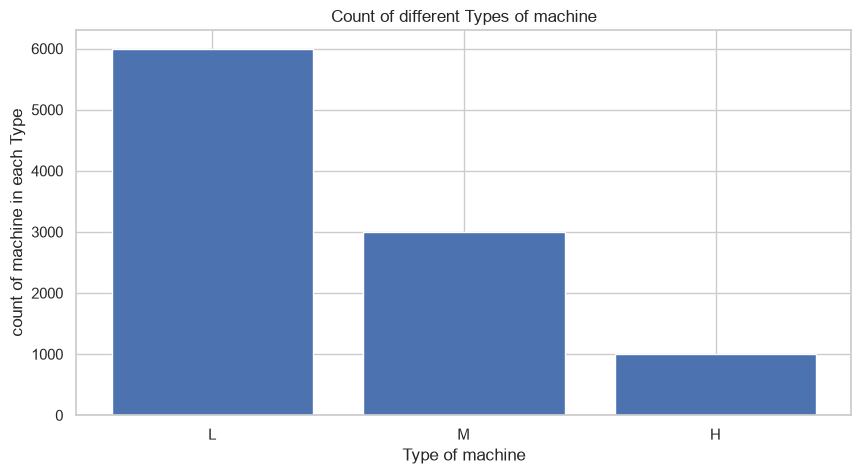

In [26]:
plt.figure(figsize=(10,5))
plt.bar(result.index,result.values,data=df)
plt.title("Count of different Types of machine")
plt.xlabel("Type of machine")
plt.ylabel("count of machine in each Type")

Text(0, 0.5, 'Count of observations')

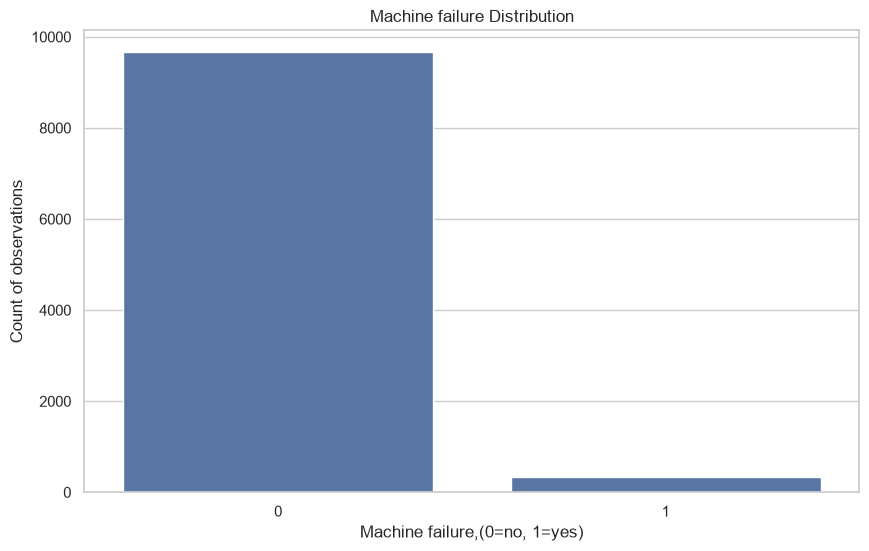

In [31]:
plt.figure(figsize=(10,6))
sns.countplot(data=df,x="Machine failure")
plt.title("Machine failure Distribution")
plt.xlabel("Machine failure,(0=no, 1=yes)")
plt.ylabel("Count of observations")



# from the above the graph we observed that the dataset is imbalanced

Text(0.5, 1.0, 'Temperature analysis')

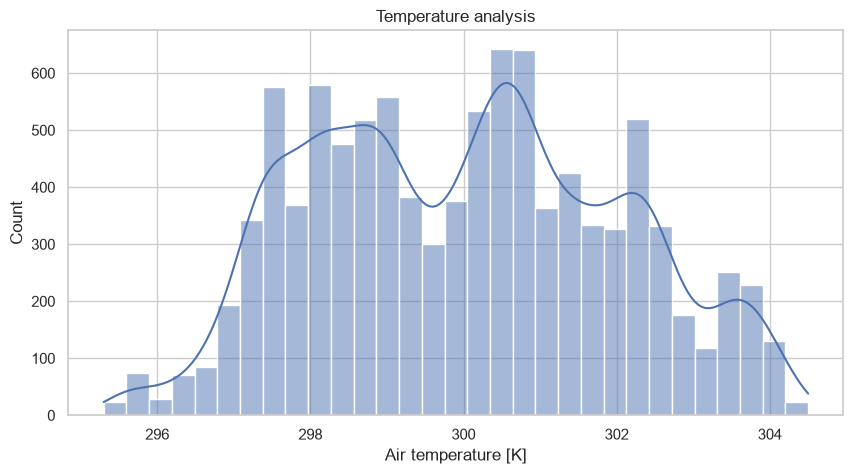

In [33]:
plt.figure(figsize=(10,5))
sns.histplot(data=df,x="Air temperature [K]",kde=True)
plt.title("Temperature analysis")

Text(0.5, 1.0, 'Machine failure vs Torque')

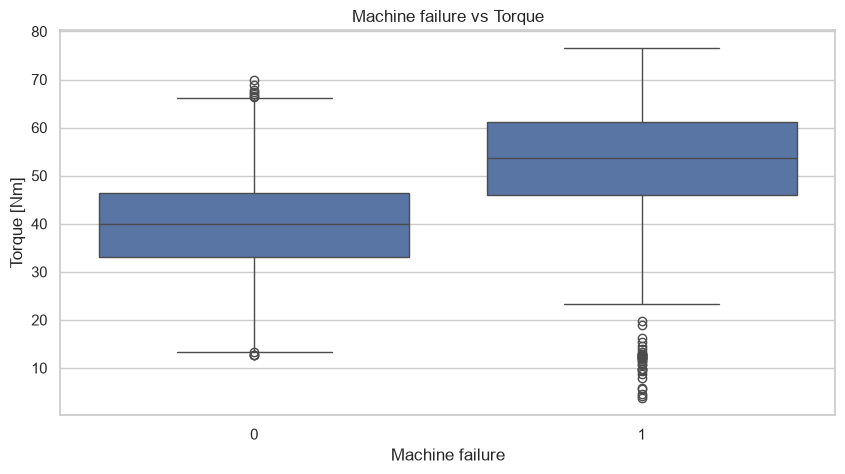

In [34]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df,x="Machine failure",y="Torque [Nm]")
plt.title("Machine failure vs Torque")

# I compared torque values between machines with and without failure using a boxplot. I observed that machines experiencing failure generally have higher median torque than machines without failure. This suggests that torque may have an important relationship with machine failure. However, there is some overlap between both groups, so torque alone is not sufficient to predict failure. We need to consider other features as well."

Text(0.5, 1.0, 'Sensor Features Correlation')

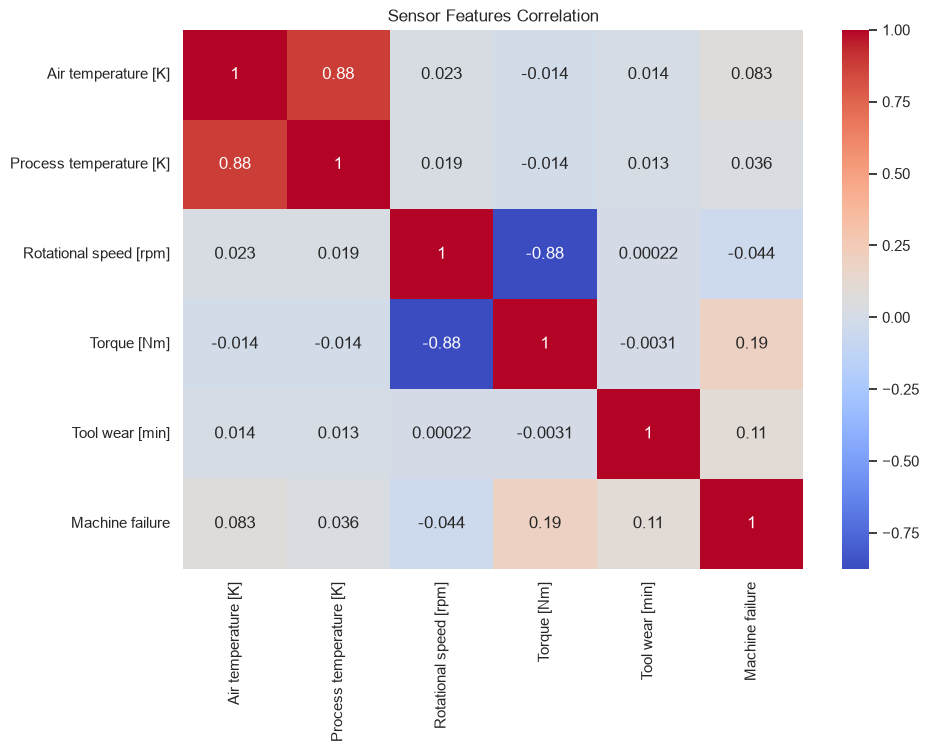

In [37]:
numeric_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]", "Machine failure"]
plt.figure(figsize=(10,7))
sns.heatmap(df[numeric_cols].corr(),annot=True,cmap="coolwarm")
plt.title("Sensor Features Correlation")

# Sensor Features Correlation – Key Observations

1. Air temperature and process temperature have a strong positive correlation (0.88).
2. Rotational speed and torque have a strong negative correlation (-0.88).
3. Torque shows the highest positive linear correlation with machine failure (0.19).
4. Tool wear has a weak positive correlation with machine failure (0.11).
5. Air temperature (0.083), process temperature (0.036), and rotational speed (-0.044) show very weak linear correlations with machine failure.

Torque and tool wear show relatively stronger linear associations with machine failure. Air temperature and process temperature are strongly correlated with each other, while rotational speed and torque also show a strong inverse relationship. Further feature importance analysis and model evaluation are required to identify the most useful predictive features.